# **Auto Tagging Support Tickets Using LLM**
### NLP / LLM Project

Automatically classify customer support tickets into categories using Large Language Models (LLMs).


# **Problem Statement & Objective**

## Problem Statement

Customer support teams receive a large number of support tickets daily.
Manually categorizing these tickets into appropriate departments such as
Billing, Technical Support, or Account Management is time-consuming and inefficient.

Large Language Models (LLMs) can automatically understand natural language
and classify tickets into relevant categories.

## Objective

The objective of this project is to build an automated system that:

• Uses Large Language Models for ticket classification  
• Applies **Zero-shot learning** to classify tickets without training  
• Applies **Few-shot prompt engineering** to improve classification performance  
• Outputs **Top 3 most probable tags for each ticket**  
• Evaluates model performance using classification metrics  
• Visualizes prediction results  

This helps organizations **automatically route support tickets to the correct department.**

# **Install Required Libraries**

In [2]:
!pip install transformers torch pandas numpy scikit-learn matplotlib seaborn
!pip install tqdm

# **Import Libraries**

In [3]:
import pandas as pd
import numpy as np

from transformers import pipeline
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm
tqdm.pandas()

# **Dataset Loading**

In [4]:
# Load dataset
df = pd.read_csv("support_tickets.csv")

df.head()

,ticket_text
0,From: lerxst@wam.umd.edu (where's my thing)\nS...
1,From: guykuo@carson.u.washington.edu (Guy Kuo)...
2,From: twillis@ec.ecn.purdue.edu (Thomas E Will...
3,From: jgreen@amber (Joe Green)\nSubject: Re: W...
4,From: jcm@head-cfa.harvard.edu (Jonathan McDow...


# **Dataset Overview**

In [5]:
print("Dataset Shape:", df.shape)
print("\nColumns:\n", df.columns)

df.info()

Dataset Shape: (11314, 1)

Columns:
 Index(['ticket_text'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11314 entries, 0 to 11313
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ticket_text  11314 non-null  object
dtypes: object(1)
memory usage: 88.5+ KB


# **Preprocessing**

In [6]:
# Rename column if needed
df.rename(columns={"text":"ticket_text"}, inplace=True)

# Remove missing values
df = df.dropna()

df.head()

,ticket_text
0,From: lerxst@wam.umd.edu (where's my thing)\nS...
1,From: guykuo@carson.u.washington.edu (Guy Kuo)...
2,From: twillis@ec.ecn.purdue.edu (Thomas E Will...
3,From: jgreen@amber (Joe Green)\nSubject: Re: W...
4,From: jcm@head-cfa.harvard.edu (Jonathan McDow...


# **Define Ticket Categories**

In [7]:
categories = [
    "Billing Issue",
    "Technical Support",
    "Account Management",
    "Feature Request",
    "Complaint",
    "General Inquiry"
]

print("Ticket Categories:", categories)

Ticket Categories: ['Billing Issue', 'Technical Support', 'Account Management', 'Feature Request', 'Complaint', 'General Inquiry']


# **Load LLM Mode**

Using HuggingFace zero-shot classifier.

In [8]:
classifier = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli"
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

# **Zero-Shot Prediction Function**

In [9]:
def zero_shot_predict(text):

    result = classifier(text, candidate_labels=categories)

    labels = result["labels"]
    scores = result["scores"]

    top3 = labels[:3]

    return top3

# **Test Zero-Shot Prediction**

In [10]:
sample_ticket = df['ticket_text'].iloc[0]

print("Ticket:")
print(sample_ticket)

print("\nPredicted Tags:")
print(zero_shot_predict(sample_ticket))

Ticket:
From: lerxst@wam.umd.edu (where's my thing)
Subject: WHAT car is this!?
Nntp-Posting-Host: rac3.wam.umd.edu
Organization: University of Maryland, College Park
Lines: 15

 I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.

Thanks,
- IL
   ---- brought to you by your neighborhood Lerxst ----






Predicted Tags:
['Feature Request', 'Complaint', 'General Inquiry']


# **Apply Zero-Shot Prediction to Dataset**

In [11]:
# Reduce dataset size for faster inference
df = df.sample(100, random_state=42)
df.reset_index(drop=True, inplace=True)

print("Dataset size used:", df.shape)

Dataset size used: (100, 1)


In [12]:
df["zero_shot_tags"] = df["ticket_text"].progress_apply(zero_shot_predict)

df.head()

100%|██████████| 100/100 [01:05<00:00,  1.54it/s]


,ticket_text,zero_shot_tags
0,From: rrn@po.CWRU.Edu (Robert R. Novitskey)\nS...,"[Complaint, Feature Request, General Inquiry]"
1,From: ardie@ux1.cso.uiuc.edu (Ardie Mack)\nSub...,"[Feature Request, General Inquiry, Complaint]"
2,From: tsa@cellar.org (The Silent Assassin)\nSu...,"[Technical Support, Billing Issue, General Inq..."
3,From: guy@idacom.hp.com (Guy M. Trotter)\nSubj...,"[Complaint, General Inquiry, Feature Request]"
4,From: jwodzia@fadel.uucp (john wodziak)\nSubje...,"[General Inquiry, Feature Request, Complaint]"


# **Few-Shot Prompt Engineering**

Few-shot examples improve prediction.

In [13]:
few_shot_examples = """
Example 1:
Ticket: I was charged twice for my subscription
Tag: Billing Issue

Example 2:
Ticket: My app keeps crashing when I open it
Tag: Technical Support

Example 3:
Ticket: I want to change my account email
Tag: Account Management
"""

# **Few-Shot Prediction Function**

In [14]:
def few_shot_predict(text):

    prompt = few_shot_examples + "\nTicket: " + text

    result = classifier(prompt, candidate_labels=categories)

    return result["labels"][:3]

# **Apply Few-Shot Prediction**

In [17]:
# Apply few-shot prediction with progress bar
df["few_shot_tags"] = df["ticket_text"].progress_apply(few_shot_predict)

df.head()

100%|██████████| 100/100 [01:25<00:00,  1.17it/s]


,ticket_text,zero_shot_tags,few_shot_tags
0,From: rrn@po.CWRU.Edu (Robert R. Novitskey)\nS...,"[Complaint, Feature Request, General Inquiry]","[Billing Issue, Account Management, Technical ..."
1,From: ardie@ux1.cso.uiuc.edu (Ardie Mack)\nSub...,"[Feature Request, General Inquiry, Complaint]","[Billing Issue, Technical Support, Account Man..."
2,From: tsa@cellar.org (The Silent Assassin)\nSu...,"[Technical Support, Billing Issue, General Inq...","[Billing Issue, Account Management, Technical ..."
3,From: guy@idacom.hp.com (Guy M. Trotter)\nSubj...,"[Complaint, General Inquiry, Feature Request]","[Account Management, Technical Support, Billin..."
4,From: jwodzia@fadel.uucp (john wodziak)\nSubje...,"[General Inquiry, Feature Request, Complaint]","[Account Management, Billing Issue, Technical ..."


# **Evaluation Metrics**

If dataset has true labels.

In [18]:
if "label" in df.columns:

    y_true = df["label"]
    y_pred = df["zero_shot_tags"].apply(lambda x: x[0])

    print("Accuracy:", accuracy_score(y_true, y_pred))

    print("\nClassification Report\n")
    print(classification_report(y_true, y_pred))

# **Visualization**

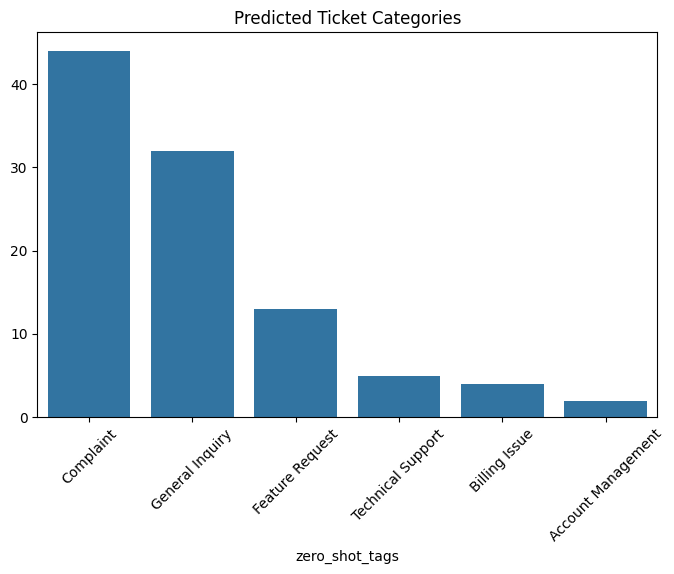

In [19]:
tag_counts = df["zero_shot_tags"].apply(lambda x: x[0]).value_counts()

plt.figure(figsize=(8,5))

sns.barplot(x=tag_counts.index, y=tag_counts.values)

plt.title("Predicted Ticket Categories")
plt.xticks(rotation=45)

plt.show()

# **Save Results**

In [20]:

output_file = "ticket_predictions.csv"

df.to_csv(output_file, index=False)

print("File saved:", output_file)

File saved: ticket_predictions.csv


In [21]:

from google.colab import files

files.download("ticket_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Final Summary**

## Final Summary / Insights

Key observations from this project:

1. Large Language Models can classify support tickets **without training data** using zero-shot learning.
2. Few-shot prompting improves classification by giving examples to the model.
3. The model successfully predicts **top 3 most relevant tags** for each ticket.
4. Visualization shows distribution of predicted ticket categories.

### Advantages

• Reduces manual effort in ticket routing  
• Improves response time for customers  
• Automatically prioritizes ticket categories  

### Future Improvements

• Fine-tuning LLMs on domain specific ticket datasets  
• Using larger instruction-tuned models  
• Integrating the system into real-time helpdesk software